# 01 — Watchlist risk labels: EDA and traditional ML

**Question this notebook answers:** after the lookup tables have done their part, can a cheap text model
(TF-IDF + a linear classifier, the "traditional ML" step) fill in the rest of the 23 risk labels well enough?
If not, which labels need the next step (encoders, then LLMs)?

**Where it sits in the roadmap**

| Step | What | Status |
|---|---|---|
| 1 | Lookup rules (list / measure / programme / FBI category → labels) | done |
| 2 | Lookup coverage on the 900 | done |
| 3 | Human-checked frozen test set | to do |
| **4a** | **Text layer bake-off: traditional ML (this notebook)** | **now** |
| 4b–c | Encoders, then prompted LLMs | next |
| 5 | Compare to agreed targets, choose | later |

**How to read it:** every output is followed by a short *Reading* note that says what the numbers mean.
The final section summarises the decision.

**Terms used throughout**

| Term | Plain meaning |
|---|---|
| positive / support | a record that has the label; *support* = how many positives exist |
| precision | of the records the model tagged with a label, the share that really have it ("how many alarms are real") |
| recall | of the records that really have the label, the share the model found ("how many did we miss") |
| F1 | one number that balances precision and recall (harmonic mean) |
| macro-F1 | average F1 over labels, every label counts the same — rare labels matter as much as common ones |
| micro-F1 | F1 over all label decisions pooled — dominated by common labels like Sanctions |
| PR-AUC | quality of the model's *ranking* for a label, independent of the cut-off; 1.0 = perfect, ≈ prevalence = random |
| threshold | the score above which we say "yes, this label"; tuned per label because labels are imbalanced |
| OOF (out-of-fold) | every record is scored by a model that never saw it during training |
| TF-IDF | turns text into numbers: a word scores high if it is frequent in this record but rare overall |
| n-gram | a run of n words (word n-grams) or n characters (char n-grams) |
| lookup ∪ model | the production design: final labels = what the lookup gives **plus** what the text model adds |

In [1]:
import json
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, average_precision_score, precision_recall_curve
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.preprocessing import FunctionTransformer, Normalizer
from sklearn.svm import LinearSVC
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80, "display.width", 200, "display.precision", 2)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

RESEARCH = Path.cwd().parent
sys.path.insert(0, str(RESEARCH / "scripts"))
from buildDataset import find_canonical
from lookupRules import record_rule_labels

SEED = 42
records = [json.loads(l) for l in open(RESEARCH / "data" / "dataset_900.jsonl", encoding="utf-8")]
LABELS = json.load(open(RESEARCH / "data" / "label_names.json", encoding="utf-8"))
SHORT = {l: l.replace("Crime-", "").split(" / ")[0].split(" & ")[0] for l in LABELS}

df = pd.DataFrame(records)
Y = np.array([[int(l in r["labels"]) for l in LABELS] for r in records])
canonical = find_canonical(records)
LOOK = np.array([[int(l in record_rule_labels(r["source"], canonical[r["record_key"]])) for l in LABELS] for r in records])

SEGMENT_OF = {
    **{s: "Sanctions & terror lists" for s in ("OFAC-SDN", "OFAC-NON-SDN", "UN-SANCTIONS", "EU-FINANCIAL-SANCTIONS",
        "EU-TRAVEL-BAN", "UKSL", "SECO-SANCTIONS", "DFAT", "EU-DESIGNATED-VESSELS", "ATC-DESIGNATED-TERRORIST-INDIVIDUALS",
        "ATC-DESIGNATED-TERRORIST-GROUPS", "US-STATE-TERRORIST-EXCLUSION")},
    **{s: "Wanted lists" for s in ("INTERPOL-RED-NOTICES", "US-MARSHALS-PROFILED-FUGITIVES", "EU-MOST-WANTED",
        "NCA-MOST-WANTED", "FBI-WANTED")},
    **{s: "Regulatory / debarment" for s in ("ADB-DEBARMENT-SUSPENSION", "AFDB-DEBARRED-ENTITIES", "WORLD-BANK-DEBARRED",
        "WORLD-BANK-OTHER-SANCTIONS", "GPPB-BLACKLISTED-ENTITIES", "CFTC-RED-LIST", "DMW-RECRUITMENT-AGENCIES")},
    **{s: "Officials & candidates" for s in ("CIA-WORLD-LEADERS-HISTORICAL", "PH-HOUSE-MEMBERS", "DILG-LOCAL-OFFICIALS",
        "COMELEC-2025-SENATORS")},
    "DNFBP": "Business register",
}
df["segment"] = df["source"].map(SEGMENT_OF)
df["part"] = df["part"].str[0]
print(f"records={len(df)}  labels={len(LABELS)}  label instances={Y.sum()}  lookup instances={(LOOK & Y).sum()}")
print("lookup gives a label the final set lacks:", int((LOOK & (1 - Y)).sum()), "(must be 0: training labels follow the rules)")

records=900  labels=23  label instances=1629  lookup instances=984
lookup gives a label the final set lacks: 0 (must be 0: training labels follow the rules)


## 1. EDA — what the data looks like
### 1.1 Where the 900 records come from
The sample was built in four parts. Only **part D (random)** reflects real-world label frequencies; part B was
picked by keywords to top up rare labels, so it over-represents them and is *easier* than reality.

In [2]:
seg_part = pd.crosstab(df["segment"], df["part"], margins=True, margins_name="total")
seg_part.columns = [{"A": "A list coverage", "B": "B rare top-up", "C": "C hard cases", "D": "D random"}.get(c, c) for c in seg_part.columns]
seg_part

,A list coverage,B rare top-up,C hard cases,D random,total
segment,,,,,
Business register,10,0,20,4,34
Officials & candidates,41,20,0,16,77
Regulatory / debarment,64,16,10,24,114
Sanctions & terror lists,179,201,16,69,465
Wanted lists,70,102,10,28,210
total,364,339,56,141,900


### 1.2 How imbalanced are the 23 labels — and how many positives does the *text* layer actually have to find?
`lookup_gives` = positives the lookup tables already produce. `text_must_find` = the rest; that is the real
learning target for any text model. `tier` uses the text-side count, because that is what the model has to learn from.

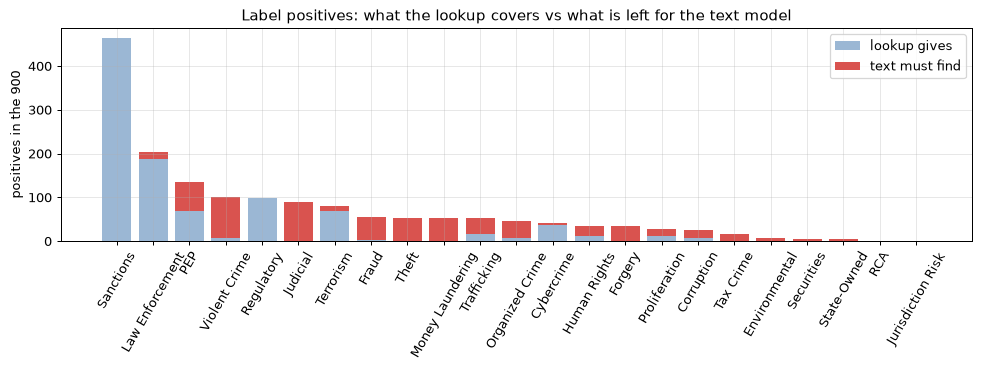

,label,positives,pct_of_900,in_part_D,lookup_gives,text_must_find,lookup_share_%,tier
0,Sanctions,464,51.56,69,463,1,99.78,lookup-driven (≥80%)
1,Law Enforcement,204,22.67,24,187,17,91.67,lookup-driven (≥80%)
2,PEP,135,15.00,26,68,67,50.37,learnable (≥50)
3,Violent Crime,102,11.33,15,7,95,6.86,learnable (≥50)
4,Regulatory,99,11.00,22,99,0,100.00,lookup-driven (≥80%)
5,Judicial,89,9.89,9,0,89,0.00,learnable (≥50)
6,Terrorism,80,8.89,12,68,12,85.00,lookup-driven (≥80%)
7,Fraud,56,6.22,2,2,54,3.57,learnable (≥50)
8,Theft,53,5.89,2,0,53,0.00,learnable (≥50)
9,Money Laundering,53,5.89,1,0,53,0.00,learnable (≥50)


In [3]:
def tier(n):
    return "learnable (≥50)" if n >= 50 else "weak (15–49)" if n >= 15 else "not measurable (<15)"

lab = pd.DataFrame({
    "label": [SHORT[l] for l in LABELS],
    "positives": Y.sum(0),
    "pct_of_900": 100 * Y.mean(0),
    "in_part_D": Y[df["part"].values == "D"].sum(0),
    "lookup_gives": (LOOK & Y).sum(0),
    "text_must_find": (Y & (1 - LOOK)).sum(0),
})
lab["lookup_share_%"] = 100 * lab["lookup_gives"] / lab["positives"].replace(0, np.nan)
lab["tier"] = ["lookup-driven (≥80%)" if s >= 80 else tier(t) for s, t in zip(lab["lookup_share_%"].fillna(0), lab["text_must_find"])]
lab = lab.sort_values("positives", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(lab["label"], lab["lookup_gives"], color="#9bb7d4", label="lookup gives")
ax.bar(lab["label"], lab["text_must_find"], bottom=lab["lookup_gives"], color="#d9534f", label="text must find")
ax.set_ylabel("positives in the 900"); ax.set_title("Label positives: what the lookup covers vs what is left for the text model")
ax.tick_params(axis="x", rotation=60); ax.legend(); plt.tight_layout(); plt.show()
lab

### 1.3 How many labels does a record carry?

In [4]:
card = pd.Series(Y.sum(1)).value_counts().sort_index()
card_seg = pd.DataFrame({"segment": df["segment"], "n": Y.sum(1)}).groupby("segment")["n"].agg(["mean", "max", lambda s: (s == 0).sum()])
card_seg.columns = ["mean_labels", "max_labels", "records_with_no_label"]
print("records by number of labels:", {int(k): int(v) for k, v in card.items()})
card_seg.sort_values("mean_labels", ascending=False)

records by number of labels: {0: 77, 1: 382, 2: 235, 3: 118, 4: 42, 5: 28, 6: 14, 7: 2, 8: 1, 9: 1}


,mean_labels,max_labels,records_with_no_label
segment,,,
Wanted lists,2.88,7,17
Sanctions & terror lists,1.82,9,0
Regulatory / debarment,0.99,3,15
Officials & candidates,0.86,1,11
Business register,0.00,0,34


### 1.4 Each segment has its own label mix (share of the segment's records with the label, %)
Rows are the list groups ("segments"). A dark cell means the label is common in that kind of list.

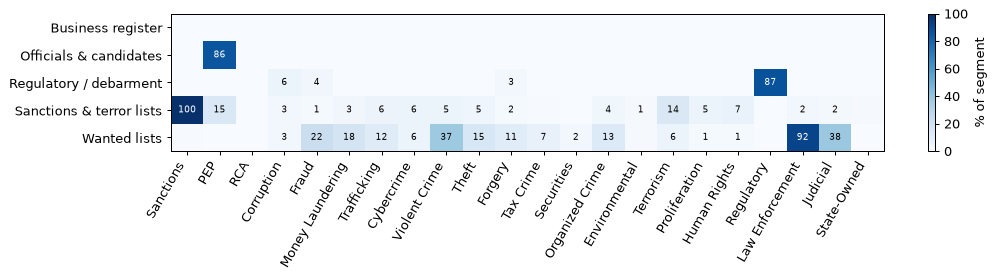

In [5]:
seg_lab = pd.DataFrame(Y, columns=[SHORT[l] for l in LABELS]).groupby(df["segment"].values).mean() * 100
seg_lab = seg_lab.loc[:, seg_lab.max() > 0]
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(seg_lab.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(seg_lab.shape[1]), seg_lab.columns, rotation=60, ha="right"); ax.set_yticks(range(len(seg_lab)), seg_lab.index)
for i in range(seg_lab.shape[0]):
    for j in range(seg_lab.shape[1]):
        v = seg_lab.values[i, j]
        if v >= 1:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.grid(False); plt.colorbar(im, ax=ax, label="% of segment"); plt.tight_layout(); plt.show()

### 1.5 Which labels travel together?
Conditional share: *of the records with label A (row), what % also have label B (column)*. Only labels with ≥15 positives.

In [6]:
keep = [i for i in range(len(LABELS)) if Y[:, i].sum() >= 15]
co = (Y[:, keep].T @ Y[:, keep]) / Y[:, keep].sum(0)[:, None] * 100
co = pd.DataFrame(co, index=[SHORT[LABELS[i]] for i in keep], columns=[SHORT[LABELS[i]] for i in keep])
pairs = [(a, b, co.loc[a, b]) for a in co.index for b in co.columns if a != b and co.loc[a, b] >= 40]
print("Strong links (≥40% of A also has B):")
for a, b, v in sorted(pairs, key=lambda x: -x[2])[:14]:
    print(f"  {a:<16} → {b:<16} {v:4.0f}%")

Strong links (≥40% of A also has B):
  Judicial         → Law Enforcement    96%
  Human Rights     → Sanctions          91%
  Proliferation    → Sanctions          89%
  Tax Crime        → Law Enforcement    88%
  Violent Crime    → Law Enforcement    82%
  Fraud            → Law Enforcement    82%
  Terrorism        → Sanctions          81%
  Theft            → Law Enforcement    79%
  Money Laundering → Law Enforcement    74%
  Forgery          → Law Enforcement    71%
  Cybercrime       → Sanctions          69%
  Tax Crime        → Fraud              65%
  Organized Crime  → Law Enforcement    64%
  Trafficking      → Sanctions          52%


### 1.6 What text is there to learn from?
Each record is rendered into sections (`Programs:`, `Remarks:`, ...). We split them into two views:
**codes** (list name, entity type, programmes, measures, additional info — what the lookup already reads) and
**narrative** (remarks, source note, occupations, titles, relationships — free text the lookup cannot read).

In [7]:
CODE_SECTIONS = ("Source list", "Entity type", "Programs", "Measures", "Additional info")
NARR_SECTIONS = ("Remarks", "Source note", "Occupations", "Titles", "Relationships")

def split_views(text):
    """Split a rendered record into (codes, narrative) text; continuation lines stay with their section."""
    views, current = {"codes": [], "narrative": []}, "narrative"
    for line in text.split("\n"):
        head = line.split(":", 1)[0]
        if head in CODE_SECTIONS:
            current = "codes"
        elif head in NARR_SECTIONS:
            current = "narrative"
        views[current].append(line.split(":", 1)[1] if head in CODE_SECTIONS + NARR_SECTIONS and ":" in line else line)
    return " ".join(views["codes"]), " ".join(views["narrative"])

df["codes"], df["narrative"] = zip(*df["text"].map(split_views))
df["narr_words"] = df["narrative"].str.split().str.len()
drop_lines = lambda t, heads: "\n".join(l for l in t.split("\n") if l.split(":", 1)[0] not in heads)
df["text_noname"] = df["text"].map(lambda t: drop_lines(t, ("Source list",)))
df["text_nocodes"] = df["text"].map(lambda t: drop_lines(t, ("Source list", "Programs")))
sec = pd.DataFrame({s: df["text"].str.contains(f"(?m)^{s}:") for s in NARR_SECTIONS}).groupby(df["segment"]).mean() * 100
sec["median_narrative_words"] = df.groupby("segment")["narr_words"].median()
sec["no_narrative_%"] = df.assign(e=df["narr_words"] == 0).groupby("segment")["e"].mean() * 100
sec.round(0)

,Remarks,Source note,Occupations,Titles,Relationships,median_narrative_words,no_narrative_%
segment,,,,,,,
Business register,0.0,85.0,15.0,0.0,0.0,1.0,0.0
Officials & candidates,4.0,0.0,100.0,0.0,0.0,12.0,0.0
Regulatory / debarment,20.0,16.0,0.0,0.0,53.0,6.0,25.0
Sanctions & terror lists,79.0,45.0,27.0,9.0,17.0,25.0,5.0
Wanted lists,67.0,8.0,8.0,0.0,0.0,84.0,33.0


In [8]:
need_text = (Y & (1 - LOOK)).sum(1) > 0
print("Records whose final labels need the text layer:", need_text.sum(), f"({need_text.mean():.0%})")
print("…of which have NO narrative text at all:", int((need_text & (df["narr_words"] == 0)).sum()))
print("Part D (random) needing the text layer:", f"{need_text[df['part'].values == 'D'].mean():.0%}")

Records whose final labels need the text layer: 363 (40%)
…of which have NO narrative text at all: 69
Part D (random) needing the text layer: 31%


## 2. Evaluation design

* **5-fold iterative stratification.** A normal random split can leave a rare label with zero positives in a fold.
  Iterative stratification (Sechidis et al., 2011) assigns records one rare label at a time so every fold gets
  its fair share of every label (`iterative-stratification` package).
* **Labels modelled:** labels with ≥15 positives. Below that (RCA 1, State-Owned 4, Securities 5, Environmental 7,
  Jurisdiction 0) a classifier cannot be trained *or* measured — each fold would hold 1–2 positives. They are reported
  as "not measurable" and must come from rules, the LLM step, or more labelled data.
* **Per-label thresholds, cross-fitted:** for fold *k*, the threshold is picked on the other folds' out-of-fold scores
  (the one that maximises F1), then applied to fold *k*. That way no record's own label chooses its own cut-off.
* **Slices:** all 900, **part D only** (honest frequencies, but small), and per segment.
* **Two scores per model:** *model alone* on all labels, and **system = lookup ∪ model** on the *text-layer labels*
  (labels where the lookup gives < 90% of positives) — that is the number that matters for production.

In [9]:
MODELLED = [i for i in range(len(LABELS)) if Y[:, i].sum() >= 15]
TEXT_LAYER = [i for i in MODELLED if (LOOK[:, i] & Y[:, i]).sum() < 0.9 * Y[:, i].sum()]
NOT_MEASURABLE = [SHORT[LABELS[i]] for i in range(len(LABELS)) if i not in MODELLED]
FOLDS = np.zeros(len(df), int)
for f, (_, te) in enumerate(MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(df, Y[:, MODELLED])):
    FOLDS[te] = f
is_D = df["part"].values == "D"

fold_tab = pd.DataFrame({f"fold {f}": Y[FOLDS == f][:, MODELLED].sum(0) for f in range(5)}, index=[SHORT[LABELS[i]] for i in MODELLED])
print("Modelled labels:", len(MODELLED), "| text-layer labels:", [SHORT[LABELS[i]] for i in TEXT_LAYER])
print("Not measurable:", NOT_MEASURABLE)
print("Positives per fold for the rarest modelled labels (should be even):")
fold_tab.loc[fold_tab.sum(1).sort_values().index[:5]]

Modelled labels: 18 | text-layer labels: ['PEP', 'Corruption', 'Fraud', 'Money Laundering', 'Trafficking', 'Cybercrime', 'Violent Crime', 'Theft', 'Forgery', 'Tax Crime', 'Organized Crime', 'Terrorism', 'Proliferation', 'Human Rights', 'Judicial']
Not measurable: ['RCA', 'Securities', 'Environmental', 'Jurisdiction Risk', 'State-Owned']
Positives per fold for the rarest modelled labels (should be even):


,fold 0,fold 1,fold 2,fold 3,fold 4
Tax Crime,3,4,3,3,4
Corruption,5,5,5,5,5
Proliferation,5,5,6,6,6
Human Rights,7,7,7,6,7
Forgery,7,7,7,6,7


In [10]:
def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

def best_threshold(y, s):
    """Score cut-off that maximises F1 on (y, s)."""
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / np.maximum(p + r, 1e-12)
    return t[np.argmax(f[:-1])] if len(t) else 0.5

def crossfit_predict(S, Yt, folds):
    """Turn OOF scores into 0/1 using per-label thresholds picked on the other folds."""
    P = np.zeros_like(Yt)
    for f in np.unique(folds):
        out, inn = folds == f, folds != f
        for j in range(Yt.shape[1]):
            P[out, j] = S[out, j] >= best_threshold(Yt[inn, j], S[inn, j])
    return P

def prf(y, p):
    tp, fp, fn = int((y & p).sum()), int(((1 - y) & p).sum()), int((y & (1 - p)).sum())
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0), tp, fp, fn

def macro_f1(Yt, P, cols):
    return np.mean([prf(Yt[:, j], P[:, j])[2] for j in cols])

def micro_f1(Yt, P):
    return prf(Yt.ravel(), P.ravel())[2]

def ml_part(Yt, P, L, cols=None):
    """Score only the model's own contribution: recall on positives the lookup missed, precision of labels it adds."""
    cols = list(range(Yt.shape[1])) if cols is None else cols
    y, p, l = Yt[:, cols], P[:, cols], L[:, cols]
    missed, added = y & (1 - l), p & (1 - l)
    rc = (missed & p).sum() / max(missed.sum(), 1); pr = (added & y).sum() / max(added.sum(), 1)
    return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0), int(missed.sum())

## 3. The models

All models are **one-vs-rest**: one small yes/no classifier per label, sharing the same text features.

| # | Model | Idea | Why try it |
|---|---|---|---|
| M1 | word TF-IDF (1–2 grams) + logistic regression | words and word pairs → weighted vote | the standard baseline; coefficients are readable |
| M2 | char TF-IDF (2–5 chars) + LR | pieces of words | robust to spelling, German/French names, plurals, codes like `SDGT` |
| M3 | word + char TF-IDF + linear SVM | max-margin version of M1+M2 | usually the strongest linear text model |
| M4 | word TF-IDF + Complement Naive Bayes | counting-based probabilities | very cheap, known to do well on imbalanced text |
| M5 | **field-segmented** TF-IDF + LR | separate vocabularies for *codes* and *narrative* | the word "terrorist" in a programme code and in a remark mean different things |
| M6 | LSA "embedding" (SVD 300 dims) + LR | compress TF-IDF into dense topic vectors | a cheap stand-in for embeddings; tests whether dense features help before we pay for encoders |
| M7 | words+chars, **narrative only** | drops list name, programmes **and** measures/additional info | upper bound on what free text alone carries |
| M8 | M2 **without the list name** | only the `Source list:` line removed | the clean memorisation test: does the model need to know *which list*? |
| M9 | M2 without list name **and programme codes** | the lookup already reads programmes | forces the model to learn conduct words, not codes |

`class_weight="balanced"` makes a missed rare positive cost as much as many missed common ones — the standard
first answer to imbalance. Thresholds (section 2) are the second answer.

In [11]:
word = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000)
char = lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=120000)
col = lambda c: FunctionTransformer(lambda X: X[c].values)
lr = lambda: LogisticRegression(C=8, class_weight="balanced", solver="liblinear", max_iter=2000)

MODELS = {
    "M1 word+LR": (lambda: make_pipeline(col("text"), word()), lr),
    "M2 char+LR": (lambda: make_pipeline(col("text"), char()), lr),
    "M3 word+char+SVM": (lambda: make_pipeline(col("text"), FeatureUnion([("w", word()), ("c", char())])),
                         lambda: LinearSVC(C=0.5, class_weight="balanced")),
    "M4 word+CNB": (lambda: make_pipeline(col("text"), word()), lambda: ComplementNB(alpha=0.3)),
    "M5 segmented+LR": (lambda: ColumnTransformer([("codes", word(), "codes"), ("narr_w", word(), "narrative"),
                                                    ("narr_c", char(), "narrative")]), lr),
    "M6 LSA300+LR": (lambda: make_pipeline(col("text"), FeatureUnion([("w", word()), ("c", char())]),
                                           TruncatedSVD(300, random_state=SEED), Normalizer()), lr),
    "M7 narrative-only+LR": (lambda: make_pipeline(col("narrative"), FeatureUnion([("w", word()), ("c", char())])), lr),
    "M8 char+LR, no list name": (lambda: make_pipeline(col("text_noname"), char()), lr),
    "M9 char+LR, no name/programmes": (lambda: make_pipeline(col("text_nocodes"), char()), lr),
}

def score(clf, X):
    if hasattr(clf, "decision_function") and not isinstance(clf, ComplementNB):
        return clf.decision_function(X)
    return clf.predict_proba(X)[:, 1]

def oof_scores(feat_factory, clf_factory, data, Yt, folds, only=None):
    """Out-of-fold scores: features fit on the training folds only, one classifier per label."""
    S = np.zeros(Yt.shape, float)
    for f in (np.unique(folds) if only is None else [only]):
        tr, te = folds != f, folds == f
        feat = feat_factory().fit(data[tr])
        Xtr, Xte = feat.transform(data[tr]), feat.transform(data[te])
        for j in range(Yt.shape[1]):
            if Yt[tr, j].min() == Yt[tr, j].max():
                S[te, j] = 1e9 if Yt[tr, j].min() else -1e9
                continue
            S[te, j] = score(clf_factory().fit(Xtr, Yt[tr, j]), Xte)
    return S

YM, LM = Y[:, MODELLED], LOOK[:, MODELLED]
TL = [MODELLED.index(i) for i in TEXT_LAYER]
results, SCORES, PREDS = [], {}, {}
for name, (ff, cf) in MODELS.items():
    t0 = time.time()
    S = oof_scores(ff, cf, df, YM, FOLDS)
    P = crossfit_predict(S, YM, FOLDS)
    SYS = P | LM
    SCORES[name], PREDS[name] = S, P
    results.append({
        "model": name,
        "macroF1 model": macro_f1(YM, P, range(len(MODELLED))),
        "microF1 model": micro_f1(YM, P),
        "macro PR-AUC": np.mean([average_precision_score(YM[:, j], S[:, j]) for j in range(len(MODELLED))]),
        "macroF1 system, text labels": macro_f1(YM, SYS, TL),
        "… part D only": macro_f1(YM[is_D], SYS[is_D], [j for j in TL if YM[is_D, j].sum() >= 3]),
        "lookup alone, text labels": macro_f1(YM, LM, TL),
        "ML part: recall": ml_part(YM, P, LM)[1],
        "ML part: precision": ml_part(YM, P, LM)[0],
        "seconds": time.time() - t0,
    })
res = pd.DataFrame(results).set_index("model")
pd.DataFrame(res).to_csv(RESEARCH / "results" / "tradml_model_summary.csv")
res.style.format("{:.3f}").format("{:.0f}", subset=["seconds"]).background_gradient(cmap="Greens", subset=res.columns[:5])

,macroF1 model,microF1 model,macro PR-AUC,"macroF1 system, text labels",… part D only,"lookup alone, text labels",ML part: recall,ML part: precision,seconds
model,,,,,,,,,
M1 word+LR,0.794,0.880,0.864,0.784,0.779,0.335,0.672,0.763,3
M2 char+LR,0.837,0.899,0.897,0.825,0.788,0.335,0.728,0.789,21
M3 word+char+SVM,0.824,0.892,0.897,0.811,0.814,0.335,0.737,0.747,27
M4 word+CNB,0.651,0.793,0.693,0.650,0.726,0.335,0.602,0.519,2
M5 segmented+LR,0.779,0.881,0.842,0.773,0.807,0.335,0.696,0.755,10
M6 LSA300+LR,0.823,0.891,0.884,0.816,0.834,0.335,0.710,0.772,32
M7 narrative-only+LR,0.539,0.708,0.562,0.568,0.645,0.335,0.500,0.395,8
"M8 char+LR, no list name",0.835,0.897,0.896,0.823,0.788,0.335,0.729,0.778,12
"M9 char+LR, no name/programmes",0.706,0.807,0.752,0.696,0.701,0.335,0.661,0.538,11


**Reading — model comparison**

* **Winner: M2 (character n-grams + logistic regression)**, system macro-F1 **0.825** on the 15 text-layer labels vs
  **0.335 for the lookup alone**. On the ML part only (label instances the lookup did not give) it finds **73%** of them,
  and **79%** of the labels it adds are correct.
* **M8 (same model, list name removed) is equal** (0.823): knowing *which list* a record came from is not needed when
  that list was in training. It matters on unseen lists — see section 7.
* **M9 (also programme lines removed) drops to 0.70**: programme lines are not just codes — they carry descriptions
  ("Narcotics Trafficking", "Human Rights Abuse") that the model legitimately uses. Keep them.
* **M7 (narrative only) 0.57** removed list name, programmes **and** measures/additional info — where Interpol keeps its
  charges. That drop is mostly *lost information*, not proof of memorisation (M8 is the clean test).
* **Characters beat words** (M2 vs M1): mixed English/German/Spanish/French, codes, and word forms
  (*launder / laundering*). M3 (SVM) and M6 (LSA) are close; Naive Bayes (M4) is clearly weaker.
* **Part D (random)** varies 0.70–0.83 between models: it has 1–15 positives per label, so differences there are noise.
* **Cost:** a full 5-fold run of M2 takes ~20 s on a laptop CPU.

## 3b. Two honest views of the same result: the whole label set vs the ML part only

The models are trained on **all** positives of each label (including those the lookup already gives), because in
production the model sees the whole record. But we score it two ways:

* **Whole label set** — what a customer finally sees: final labels = lookup ∪ model, over **all 23 labels and all
  label instances**. Rare labels the model cannot produce count as misses here.
* **ML part only** — only the label instances the lookup did **not** give. *Recall* = of the positives the lookup missed,
  the share the model found. *Precision* = of the labels the model **added** on top of the lookup, the share that are correct.

The rows also show the effect of the 5 rare labels: with them (all 23) and without them (18 modelled labels).

In [12]:
BEST = res.drop(index="M7 narrative-only+LR")["macroF1 system, text labels"].idxmax()
print("best model by system macro-F1 on text-layer labels:", BEST)
P23 = np.zeros_like(Y); P23[:, MODELLED] = PREDS[BEST]
SYS23 = P23 | LOOK
groups = {
    "All 23 labels": list(range(len(LABELS))),
    "18 modelled labels (5 rare removed)": MODELLED,
    "3 lookup-driven labels": [i for i in MODELLED if i not in TEXT_LAYER],
    "15 text-layer labels": TEXT_LAYER,
    "5 rare labels only": [i for i in range(len(LABELS)) if i not in MODELLED],
}
view = []
for g, cols in groups.items():
    inst = int(Y[:, cols].sum())
    pr, rc, f1, *_ = prf(Y[:, cols].ravel(), SYS23[:, cols].ravel())
    mpr, mrc, mf1, missed = ml_part(Y, P23, LOOK, cols)
    view.append({"labels": g, "label instances": inst, "% of all instances": 100 * inst / Y.sum(),
                 "from lookup %": 100 * (Y[:, cols] & LOOK[:, cols]).sum() / max(inst, 1),
                 "WHOLE: precision": pr, "WHOLE: recall": rc, "WHOLE: micro-F1": f1,
                 "WHOLE: macro-F1": np.mean([prf(Y[:, i], SYS23[:, i])[2] for i in cols]),
                 "ML part: instances": missed, "ML part: recall": mrc, "ML part: precision": mpr, "ML part: F1": mf1})
view = pd.DataFrame(view).set_index("labels")
view.to_csv(RESEARCH / "results" / "tradml_whole_vs_ml_part.csv")
view.style.format("{:.2f}").format("{:.0f}", subset=["label instances", "% of all instances", "from lookup %", "ML part: instances"])

best model by system macro-F1 on text-layer labels: M2 char+LR


,label instances,% of all instances,from lookup %,WHOLE: precision,WHOLE: recall,WHOLE: micro-F1,WHOLE: macro-F1,ML part: instances,ML part: recall,ML part: precision,ML part: F1
labels,,,,,,,,,,,
All 23 labels,1629,100,60,0.92,0.88,0.90,0.67,645,0.71,0.79,0.75
18 modelled labels (5 rare removed),1612,99,61,0.92,0.89,0.91,0.85,628,0.73,0.79,0.76
3 lookup-driven labels,767,47,98,0.99,0.98,0.99,0.98,18,0.33,0.43,0.38
15 text-layer labels,845,52,28,0.86,0.81,0.83,0.83,610,0.74,0.80,0.77
5 rare labels only,17,1,0,0.00,0.00,0.00,0.00,17,0.00,0.00,0.00


**Reading — whole label set vs ML part (answers "is the ML part a minority?")**

* **The ML part is not a minority: 645 of 1,629 label instances (40%) are ones the lookup does not give.** The lookup
  gives 60%, almost all of it Sanctions, Law Enforcement and Regulatory.
* **Whole label set (what a customer sees), all 23 labels:** precision 0.92, recall 0.88, micro-F1 0.90.
  This looks good *because* 60% of instances come from near-perfect rules.
* **ML part only:** recall **0.71**, precision **0.79**, F1 0.75 — this is the honest quality of the model itself.
  Roughly **3 in 10 labels the lookup cannot give are missed**, and 1 in 5 labels the model adds is wrong.
* **Micro vs macro:** micro-F1 counts every label instance (dominated by Sanctions); macro-F1 averages the labels.
  Macro-F1 is 0.67 with the 5 rare labels and **0.85 without them**, because each rare label scores 0 and counts 1/23 of the
  average. In instance terms they are only **17 of 1,629 (1%)** — tiny for overall recall, big for the macro average.
* **Which number to report:** both, always side by side — the whole set for the product, the ML part for choosing the model.

## 4. Best model, label by label
For each modelled label: support, precision and recall with their 95% intervals (how much these could move with
a different sample), F1, PR-AUC, and **R@P90** — the recall we would get if we demanded 90% precision.
R@P90 is optimistic (read straight off the out-of-fold PR curve) but shows how far each label is from a bank-grade bar.

In [13]:
S, P = SCORES[BEST], PREDS[BEST]
SYS = P | LM

def r_at_p(y, s, target=0.9):
    p, r, _ = precision_recall_curve(y, s)
    ok = r[p >= target]
    return ok.max() if len(ok) else 0.0

rows = []
for j, i in enumerate(MODELLED):
    pr, rc, f1, tp, fp, fn = prf(YM[:, j], P[:, j])
    sp, sr, sf, *_ = prf(YM[:, j], SYS[:, j])
    rows.append({
        "label": SHORT[LABELS[i]], "support": int(YM[:, j].sum()), "lookup share": LM[:, j].sum() / YM[:, j].sum(),
        "P": pr, "P 95% CI": "{:.2f}–{:.2f}".format(*wilson(tp, tp + fp)),
        "R": rc, "R 95% CI": "{:.2f}–{:.2f}".format(*wilson(tp, tp + fn)),
        "F1": f1, "PR-AUC": average_precision_score(YM[:, j], S[:, j]), "R@P90": r_at_p(YM[:, j], S[:, j]),
        "system P": sp, "system R": sr, "text layer": "yes" if i in TEXT_LAYER else "",
    })
per_label = pd.DataFrame(rows).sort_values("support", ascending=False).set_index("label")
per_label.to_csv(RESEARCH / "results" / "tradml_best_per_label.csv")
per_label.style.format({c: "{:.2f}" for c in ["lookup share", "P", "R", "F1", "PR-AUC", "R@P90", "system P", "system R"]}) \
    .background_gradient(cmap="RdYlGn", vmin=0.5, vmax=1, subset=["F1", "R@P90", "system R"])

,support,lookup share,P,P 95% CI,R,R 95% CI,F1,PR-AUC,R@P90,system P,system R,text layer
label,,,,,,,,,,,,
Sanctions,464,1.00,1.00,0.98–1.00,0.99,0.98–1.00,0.99,1.00,1.00,1.00,1.00,
Law Enforcement,204,0.92,0.98,0.95–0.99,0.95,0.91–0.97,0.96,0.99,0.99,0.98,0.95,
PEP,135,0.50,0.82,0.74–0.88,0.76,0.68–0.83,0.79,0.91,0.73,0.82,0.78,yes
Violent Crime,102,0.07,0.85,0.77–0.91,0.84,0.76–0.90,0.85,0.92,0.76,0.85,0.84,yes
Regulatory,99,1.00,0.98,0.93–0.99,0.98,0.93–0.99,0.98,1.00,0.99,0.98,1.00,
Judicial,89,0.00,0.84,0.75–0.90,0.82,0.73–0.89,0.83,0.90,0.76,0.84,0.82,yes
Terrorism,80,0.85,0.88,0.80–0.93,0.94,0.86–0.97,0.91,0.98,0.94,0.89,0.97,yes
Fraud,56,0.04,0.96,0.87–0.99,0.89,0.79–0.95,0.93,0.97,0.91,0.96,0.89,yes
Theft,53,0.00,0.76,0.61–0.87,0.60,0.47–0.72,0.67,0.77,0.51,0.76,0.60,yes


**Reading — per label (M2)**

| Group | Labels | What it means |
|---|---|---|
| **Solved by lookup** | Sanctions 0.99, Regulatory 0.98, Law Enforcement 0.96 | the model just re-learns the rule; production keeps the rule |
| **Good, not bank-grade** (F1 0.83–0.93) | Fraud, Terrorism, Proliferation, Human Rights, Violent Crime, Money Laundering, Cybercrime, Judicial | precise, but recall 0.77–0.94 |
| **Weak** (F1 ≤ 0.80) | Trafficking, Corruption, PEP, Forgery, Organized Crime, **Theft 0.67**, **Tax 0.63** | overlapping definitions and few positives |

* **Read the intervals.** Tax Crime precision 0.61 has a 95% range of 0.39–0.80: 17 positives are too few to judge.
* **R@P90** (recall if 90% of alerts must be correct): Tax 0.12, Theft 0.51, Organized Crime 0.58 — far from bank-grade.
* **No text-layer label reaches recall 0.95.**

## 5. Lookup alone vs model alone vs lookup ∪ model (text-layer labels)
Recall here = of all positives of that label, the share found. The gap between the grey and the green bar is
what the text model adds on top of the tables.

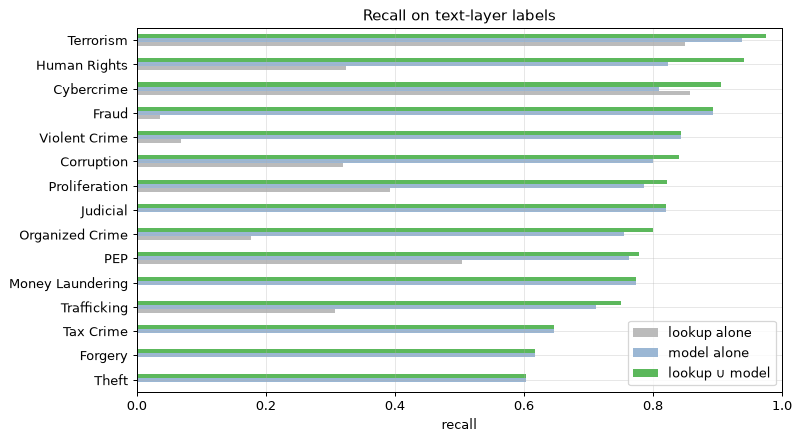

,lookup alone,model alone,lookup ∪ model,system precision
Theft,0.00,0.60,0.60,0.76
Forgery,0.00,0.62,0.62,0.95
Tax Crime,0.00,0.65,0.65,0.61
Trafficking,0.31,0.71,0.75,0.91
Money Laundering,0.00,0.77,0.77,0.93
PEP,0.50,0.76,0.78,0.82
Organized Crime,0.18,0.76,0.80,0.73
Judicial,0.00,0.82,0.82,0.84
Proliferation,0.39,0.79,0.82,1.00
Corruption,0.32,0.80,0.84,0.81


In [14]:
comp = pd.DataFrame({
    "lookup alone": [prf(YM[:, j], LM[:, j])[1] for j in TL],
    "model alone": [prf(YM[:, j], P[:, j])[1] for j in TL],
    "lookup ∪ model": [prf(YM[:, j], SYS[:, j])[1] for j in TL],
    "system precision": [prf(YM[:, j], SYS[:, j])[0] for j in TL],
}, index=[SHORT[LABELS[MODELLED[j]]] for j in TL]).sort_values("lookup ∪ model")
ax = comp[["lookup alone", "model alone", "lookup ∪ model"]].plot.barh(figsize=(9, 5), color=["#bbbbbb", "#9bb7d4", "#5cb85c"])
ax.set_xlabel("recall"); ax.set_xlim(0, 1); ax.set_title("Recall on text-layer labels"); plt.tight_layout(); plt.show()
comp.round(2)

**Reading — what the model adds to the lookup**

* For labels the lookup never gives (Judicial, Money Laundering, Theft, Forgery, Tax) all recall comes from the model.
* For partly-coded labels the union beats both sides: Human Rights 0.32 (lookup) → 0.82 (model) → **0.94** (union);
  Cybercrime 0.86 → 0.81 → 0.90; Terrorism 0.85 → 0.94 → 0.98. Lookup and model miss *different* records.
* Precision is high on Proliferation 1.00, Fraud 0.96, Forgery 0.95, Money Laundering 0.93; low on Tax 0.61,
  Organized Crime 0.73, Theft 0.76.

## 6. Segmentation
Three questions: (a) does quality differ by list group? (b) would one model **per segment** beat one global model?
(c) does an unsupervised "embedding" segmentation find meaningful groups?

### 6a. Best model's quality per segment (system = lookup ∪ model, labels with ≥5 positives in that segment)

In [15]:
seg_rows = []
for seg in sorted(df["segment"].unique()):
    m = df["segment"].values == seg
    cols = [j for j in range(len(MODELLED)) if YM[m, j].sum() >= 5]
    tcols = [j for j in cols if j in TL]
    seg_rows.append({"segment": seg, "records": int(m.sum()), "labels ≥5 pos": len(cols),
                     "macroF1 system": macro_f1(YM[m], SYS[m], cols) if cols else np.nan,
                     "macroF1 system, text labels": macro_f1(YM[m], SYS[m], tcols) if tcols else np.nan,
                     "exact-match records %": 100 * (SYS[m] == YM[m]).all(1).mean()})
pd.DataFrame(seg_rows).set_index("segment").round(2)

,records,labels ≥5 pos,macroF1 system,"macroF1 system, text labels",exact-match records %
segment,,,,,
Business register,34,0,NaN,NaN,100.00
Officials & candidates,77,1,1.00,1.00,100.00
Regulatory / debarment,114,2,0.92,0.86,94.74
Sanctions & terror lists,465,16,0.81,0.82,74.84
Wanted lists,210,13,0.82,0.81,50.00


### 6b. Global model vs one model per segment
Same folds, same features; the per-segment model only sees its own segment's training records.

In [16]:
seg_cmp = []
ff, cf = MODELS[BEST]
for seg in ["Sanctions & terror lists", "Wanted lists"]:
    m = df["segment"].values == seg
    cols = [j for j in TL if YM[m, j].sum() >= 10]
    S_seg = oof_scores(ff, cf, df[m], YM[m][:, cols], FOLDS[m])
    P_seg = crossfit_predict(S_seg, YM[m][:, cols], FOLDS[m]) | LM[m][:, cols]
    seg_cmp.append({"segment": seg, "labels compared": ", ".join(SHORT[LABELS[MODELLED[j]]] for j in cols),
                    "global model": macro_f1(YM[m][:, cols], SYS[m][:, cols], range(len(cols))),
                    "per-segment model": macro_f1(YM[m][:, cols], P_seg, range(len(cols)))})
pd.DataFrame(seg_cmp).set_index("segment").round(3)

,labels compared,global model,per-segment model
segment,,,
Sanctions & terror lists,"PEP, Corruption, Money Laundering, Trafficking, Cybercrime, Violent Crime, T...",0.82,0.79
Wanted lists,"Fraud, Money Laundering, Trafficking, Cybercrime, Violent Crime, Theft, Forg...",0.81,0.78


### 6c. Unsupervised segmentation of the narrative text (LSA embedding + k-means)
We embed only the **narrative** (so the list name cannot drive the clusters), cluster into 8 groups, and look at
each cluster's top words, dominant labels and dominant list group. ARI (adjusted Rand index) compares the clusters
with the list groups: 0 = unrelated, 1 = identical.

In [17]:
has_n = df["narr_words"].values > 0
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english")
Xn = tf.fit_transform(df.loc[has_n, "narrative"])
Zn = Normalizer().fit_transform(TruncatedSVD(100, random_state=SEED).fit_transform(Xn))
km = KMeans(8, n_init=10, random_state=SEED).fit(Zn)
terms = np.array(tf.get_feature_names_out())
cl_rows = []
for c in range(8):
    m = km.labels_ == c
    centroid = np.asarray(Xn[m].mean(0)).ravel()
    lab_share = Y[has_n][m].mean(0)
    top_labels = ", ".join(f"{SHORT[LABELS[i]]} {lab_share[i]:.0%}" for i in np.argsort(-lab_share)[:3] if lab_share[i] >= 0.15)
    cl_rows.append({"cluster": c, "records": int(m.sum()), "top words": ", ".join(terms[np.argsort(-centroid)[:6]]),
                    "main labels": top_labels, "main segment": "{} {:.0%}".format(*next(iter(df.loc[has_n, "segment"][m].value_counts(normalize=True).items())))})
print(f"records with narrative: {has_n.sum()}  |  ARI(clusters, list groups) = {adjusted_rand_score(df.loc[has_n, 'segment'], km.labels_):.2f}")
pd.DataFrame(cl_rows).set_index("cluster")

records with narrative: 778  |  ARI(clusters, list groups) = 0.21


,records,top words,main labels,main segment
cluster,,,,
0,32,"min, government min, government, min state, nuclear, state",PEP 100%,Officials & candidates 100%
1,36,"sanctions, secondary, secondary sanctions, sdn, executive order, executive","Sanctions 100%, Terrorism 31%, Proliferation 19%",Sanctions & terror lists 100%
2,47,"security council, council, security, interpol, special, notice","Sanctions 98%, Terrorism 47%",Sanctions & terror lists 98%
3,61,"district, states, united states, wanted, warrant, summary","Law Enforcement 98%, Judicial 87%, Fraud 44%",Wanted lists 100%
4,47,"summary, seen, victim, police, area, remarks","Law Enforcement 66%, Violent Crime 53%, Judicial 21%",Wanted lists 100%
5,22,"persons, sanctions, autonomous sanctions, instrument, autonomous, designated...","Sanctions 100%, Cybercrime 32%",Sanctions & terror lists 100%
6,24,"represented, mr, ii, jr, year old, year",Regulatory 42%,Regulatory / debarment 100%
7,509,"list, info, additional info, additional, sdn, owned","Sanctions 66%, PEP 18%",Sanctions & terror lists 66%


**Reading — segmentation**

* **(a)** Officials and the business register are trivial (100% of records fully right), regulatory lists 95%, sanctions 75%.
  **Wanted lists are the hard segment: only 50% of records get every label right** (2.9 labels per record, multilingual charges).
* **(b) One model per segment is worse** (0.79 vs 0.82 on sanctions, 0.78 vs 0.81 on wanted lists): with 900 records,
  splitting the data costs more than specialising gains. **Keep one global model; use segments for reporting, thresholds
  and review routing.**
* **(c) Clusters do not give labels** (ARI 0.21; one 509-record boilerplate cluster). Some clusters are meaningful
  (ministers → PEP 100%; US warrants → Judicial 87%) but mostly mirror *how each source writes*. Useful for stratified
  sampling of the human test set, not as a classifier.

## 7. Does it generalise to a list it has never seen? (leave-one-list-out, every list)
Each of the 29 lists is held out in turn: features and classifiers are trained on the other 28, thresholds come from
the 5-fold run, and the held-out list is scored as **lookup ∪ model**. This simulates onboarding a new watchlist.
Scores are pooled over all lists and reported on the **ML part** (positives the lookup missed / labels the model added),
because on a new list the lookup rules would be written first and the model must do the rest.

Three variants of M2 answer "does the model memorise lists?": with the list name (M2), without it (M8),
and without list name and programme codes (M9).

In [18]:
LOLO_MODELS = ["M2 char+LR", "M8 char+LR, no list name", "M9 char+LR, no name/programmes"]
lolo_rows, lolo_label = [], {}
for name in LOLO_MODELS:
    ff_v, cf_v = MODELS[name]
    thr = np.array([[best_threshold(YM[FOLDS != f, j], SCORES[name][FOLDS != f, j]) for j in range(len(MODELLED))] for f in range(5)]).mean(0)
    P_l = np.zeros_like(YM)
    for src in df["source"].unique():
        m = (df["source"] == src).values
        P_l[m] = oof_scores(ff_v, cf_v, df, YM, np.where(m, 0, 1), only=0)[m] >= thr
    pr, rc, f1, missed = ml_part(YM, P_l, LM, TL)
    pr0, rc0, f10, _ = ml_part(YM, PREDS[name], LM, TL)
    lolo_rows.append({"model": name, "seen lists: ML recall": rc0, "seen: ML precision": pr0, "seen: ML F1": f10,
                      "UNSEEN lists: ML recall": rc, "unseen: ML precision": pr, "unseen: ML F1": f1,
                      "unseen: system macro-F1, text labels": macro_f1(YM, P_l | LM, TL)})
    lolo_label[name] = [ml_part(YM, P_l, LM, [j])[1] for j in TL]
    if name == LOLO_MODELS[0]:
        by_seg = pd.DataFrame({"segment": df["segment"], "missed": (YM & (1 - LM))[:, TL].sum(1),
                               "found": (YM & (1 - LM) & P_l)[:, TL].sum(1)}).groupby("segment").sum()
lolo_tab = pd.DataFrame(lolo_rows).set_index("model")
lolo_tab.to_csv(RESEARCH / "results" / "tradml_unseen_lists.csv")
lolo_tab.round(3)

,seen lists: ML recall,seen: ML precision,seen: ML F1,UNSEEN lists: ML recall,unseen: ML precision,unseen: ML F1,"unseen: system macro-F1, text labels"
model,,,,,,,
M2 char+LR,0.74,0.80,0.77,0.43,0.83,0.56,0.65
"M8 char+LR, no list name",0.74,0.79,0.76,0.48,0.79,0.59,0.67
"M9 char+LR, no name/programmes",0.66,0.56,0.60,0.38,0.57,0.46,0.54


In [19]:
per_lab = pd.DataFrame(lolo_label, index=[SHORT[LABELS[MODELLED[j]]] for j in TL])
per_lab.insert(0, "seen (M2)", [ml_part(YM, PREDS["M2 char+LR"], LM, [j])[1] for j in TL])
per_lab.insert(0, "ML-part positives", [int((YM & (1 - LM))[:, j].sum()) for j in TL])
by_seg["unseen recall (M2)"] = by_seg["found"] / by_seg["missed"].replace(0, np.nan)
print("Unseen-list ML-part recall by segment (M2):")
print(by_seg.round(2).to_string())
per_lab.sort_values("seen (M2)").round(2)

Unseen-list ML-part recall by segment (M2):
                          missed  found  unseen recall (M2)
segment                                                    
Business register              0      0                 NaN
Officials & candidates         0      0                 NaN
Regulatory / debarment        14      3                0.21
Sanctions & terror lists     219     97                0.44
Wanted lists                 377    160                0.42


,ML-part positives,seen (M2),M2 char+LR,"M8 char+LR, no list name","M9 char+LR, no name/programmes"
Cybercrime,6,0.33,0.33,0.33,0.00
PEP,67,0.55,0.57,0.55,0.63
Theft,53,0.60,0.36,0.43,0.25
Forgery,34,0.62,0.03,0.15,0.00
Trafficking,36,0.64,0.50,0.50,0.39
Tax Crime,17,0.65,0.12,0.18,0.18
Proliferation,17,0.71,0.29,0.24,0.29
Organized Crime,37,0.76,0.51,0.51,0.08
Corruption,17,0.76,0.29,0.12,0.29
Money Laundering,53,0.77,0.49,0.51,0.32


**Reading — unseen lists (the key weakness)**

* On the ML part, recall falls from **0.74 (seen lists) to 0.43 (unseen)** for M2. Precision holds (0.83), so the model
  is not guessing wildly — it simply stays silent on wording it has not seen.
  *(The 0.61 in the previous version also counted positives the lookup already gave; 0.43 is the honest ML-only figure.)*
* **"Memorises lists" — what it really means:** removing the list name (M8) costs nothing on seen lists but lifts unseen
  recall 0.43 → **0.48**, and Judicial 0.27 → 0.42, Violent 0.44 → 0.59. So the name *is* used as a shortcut, but most of
  the gap is **source style**: each list phrases charges in its own way (Interpol: short Spanish/French upper-case charges;
  FBI: long US court summaries). A model trained on 28 lists has not seen list 29's phrasing.
* **Collapses on unseen lists:** Forgery 0.62 → 0.03, Tax 0.65 → 0.12, Corruption 0.76 → 0.29, Proliferation 0.71 → 0.29.
  These labels rely on words that appear in few lists. Human Rights (0.78) and Fraud (0.63) transfer best.
* Both large segments are equally affected (sanctions 0.44, wanted 0.42).
* **Implication:** TF-IDF only knows words it has seen. Generalising to new lists needs prior language knowledge
  (pre-trained, multilingual encoders or an LLM reading the label definitions). **Unseen-list ML recall is the headline
  metric for the next steps.**

## 8. What the model learned (explainability)
Top words pushing each text-layer label up, from the M1 logistic regression trained on all 900 (word features are
readable; char features are not). Sensible words = the model reads conduct; list names or IDs = it memorises sources.

In [20]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(df["text"])
Xall, vocab = vec.transform(df["text"]), np.array(vec.get_feature_names_out())
expl = {}
for i in TEXT_LAYER:
    w = lr().fit(Xall, Y[:, i]).coef_.ravel()
    expl[SHORT[LABELS[i]]] = ", ".join(vocab[np.argsort(-w)[:10]])
pd.Series(expl, name="top 10 words").to_frame()

,top 10 words
PEP,"minister, former, minister of, occupations, president, committee, occupation..."
Corruption,"corrupt, practices, 30 00, corruption, active corrupt, 2022 03, 03 30, corru..."
Fraud,"fraud, fraudulent, forgery, cheating, tax fraud, enforcement fraud, active f..."
Money Laundering,"laundering, money, money laundering, proceeds, launder, the proceeds, and mo..."
Trafficking,"trafficking, drugs, illicit, narcotics, drug, illicit drugs, to distribute, ..."
Cybercrime,"cyber, computer, to computer, data, access, unauthorized access, unauthorize..."
Violent Crime,"murder, kidnapping, rape, at, assault, armed, de, armed robbery, homicidio, ..."
Theft,"robbery, misappropriation, armed robbery, criminal, theft, enforcement misap..."
Forgery,"forgery, counterfeit, documents, counterfeit currency, currency, invoice, fr..."
Tax Crime,"tax, taxes, fraud, tax fraud, tax evasion, evasion, money laundering, enforc..."


**Reading — learned words** (word model on the full text, list name included, to expose shortcuts)

* Most labels learned the right vocabulary (Money Laundering → *laundering, proceeds*; Cybercrime → *unauthorized access*).
* **Shortcut words:** Terrorism → `sv`, `taqa`, `13224` (codes the lookup already handles); Corruption → `30 00`, `2022 03`
  (one designation batch's dates); Organized Crime → `haiti`, `13581` (one OFAC programme); Judicial → *he, was, years*
  (US court-summary style). These do not transfer to new lists — consistent with section 7.

## 9. Error analysis — what the misses look like
Three of the hardest text-layer labels, two misses (false negatives) and one false alarm (false positive) each,
narrative cut to 260 characters.

In [21]:
hard = per_label[per_label["text layer"] == "yes"].sort_values("F1").index[:3]
for name in hard:
    j = [SHORT[LABELS[i]] for i in MODELLED].index(name)
    fn = np.flatnonzero((YM[:, j] == 1) & (SYS[:, j] == 0))[:2]
    fp = np.flatnonzero((YM[:, j] == 0) & (SYS[:, j] == 1))[:1]
    print(f"\n=== {name}: {len(np.flatnonzero((YM[:, j]==1)&(SYS[:, j]==0)))} missed, {len(np.flatnonzero((YM[:, j]==0)&(SYS[:, j]==1)))} false alarms")
    for kind, idx in (("MISSED", fn), ("FALSE ALARM", fp)):
        for k in idx:
            r = df.iloc[k]
            print(f"  [{kind}] {r['source']} | labels: {', '.join(SHORT[l] for l in r['labels'])}")
            print("     ", (r["narrative"] or r["codes"])[:260].replace("\n", " "))


=== Tax Crime: 6 missed, 7 false alarms
  [MISSED] US-MARSHALS-PROFILED-FUGITIVES | labels: Fraud, Tax Crime, Law Enforcement, Judicial
       Summary ; Original Charge: Tax Fraud
  [MISSED] FBI-WANTED | labels: Tax Crime, Law Enforcement, Judicial
       It is believed that Nader owns two restaurants in Batroun, Lebanon.  One of the restaurants is called Cheers Cousin Mike.  Summary ; Income Tax Evasion (Four Counts) || Remarks ; Nakhle Nader is wanted on four counts of income tax evasion. From about October 
  [FALSE ALARM] INTERPOL-RED-NOTICES | labels: Violent Crime, Law Enforcement
       INTERPOL-RED-NOTICES  Individual  Law Enforcement ; Asesinato ; GT || Law Enforcement ; Evasión ; GT

=== Theft: 21 missed, 10 false alarms
  [MISSED] NCA-MOST-WANTED | labels: Trafficking, Violent Crime, Theft, Law Enforcement
       We pursue wanted fugitives all around the world, but we need your help to bring them to justice. If you have any information about a wanted fugitive please report 

**Reading — errors**

* **Too few examples:** "Original Charge: Tax Fraud" and "Income Tax Evasion" were missed as Tax Crime although the
  words are right there — 17 training positives are not enough.
* **Multilingual false friend:** Interpol `Evasión` (Spanish for *escape*) was flagged as Tax Crime because its
  characters match *evasion*. Character n-grams help with languages but cannot know meaning.
* **No evidence in the text:** the UKSL Theft record has an empty narrative (`""`); the NCA record's only text is site
  boilerplate. Either the labeller saw information the rendered text lacks, or the label is wrong — label-review list.
* **Definition boundaries:** Sinaloa Cartel support and a "gang leader" missed as Organized Crime; a drug network flagged
  as Theft. A model that reads the label definitions (LLM) helps most here.

## 10. Conclusions

| Question | Answer |
|---|---|
| Is the ML part a minority? | **No — 40% of label instances** (645 / 1,629) are not given by the lookup. |
| Whole label set quality (lookup ∪ M2) | precision 0.92, recall 0.88, micro-F1 0.90 (23 labels) |
| ML part quality (what the model alone adds) | recall 0.71, precision 0.79 — 3 in 10 missed |
| Effect of the 5 rare labels | 1% of instances; macro-F1 0.67 with them, 0.85 without |
| Best traditional model | char TF-IDF + logistic regression, class-balanced, per-label thresholds; **drop the list name (M8)** |
| Unseen lists | ML recall 0.74 → 0.43 (0.48 without list name). **Main weakness.** |
| Segmentation | one global model; segments for evaluation, thresholds, review routing |

**Rare labels — what can be done without new labelled data**

| Label | Practical source |
|---|---|
| Jurisdiction Risk | not a text problem: a **country lookup** (FATF / EU high-risk country lists) on nationality / address |
| State-Owned | structured relationships ("owned or controlled by the Government of …") → rule on `Relationships` + LLM check |
| RCA | `Relationships` to a PEP (relative / close associate) → rule, needs the linked PEP record |
| Securities, Environmental | keyword search over **all** watchlist records (insider trading, market manipulation; wildlife, poaching, illegal logging) to find candidates → label those → enough positives to train and measure |

**Next steps**
1. **Encoder step** on the same folds and metrics, with **unseen-list ML recall** as the headline; include a multilingual model.
2. **Human-checked test set:** over-sample weak labels, Interpol / wanted lists, and rare-label candidates.
3. **Label review** for records whose label has no evidence in the text.
4. Agree targets before testing; tune thresholds for **recall**, send low-confidence records to review or the LLM.

*Caveat:* labels come from LLM labellers and part B was keyword-selected, so rare-label scores are optimistic.